# What makes a music artist successful?
**Programming for Data Science 2026/2027 — Group Project**

| Name | Student number |
| --- | --- |
| Name 1 | 2025XXXXX |
| Name 2 | 2025XXXXX |
| Name 3 | 2025XXXXX |
| Name 4 | 2025XXXXX |

GitHub repository: *link here*

### <font color='#BFD72F'>Table of Contents </font> <a class="anchor" id='toc'></a>

- [0. Setup](#P0)
- [1. Data Wrangling and Analysis](#P1)
    - [1.1 Data quality (Q1)](#P1.1)
    - [1.2 Artist profile (Q2)](#P1.2)
    - [1.3 Update dates (Q3)](#P1.3)
    - [1.4 Career length and collaborations (Q4)](#P1.4)
    - [1.5 Additional insights (Q5)](#P1.5)
- [2. Advanced Topic - Interactive Maps](#P2)
    - [2.1 Web scraping](#P2.1)
    - [2.2 Interactive maps](#P2.2)
- [3. Data Science in Action](#P3)
    - [3.1 New variables](#P3.1)
    - [3.2 Streaming-era momentum](#P3.2)
    - [3.3 Similar artist recommender](#P3.3)
- [4. Conclusions](#P4)

### <font color='#BFD72F'>0. Setup </font> <a class="anchor" id="P0"></a>
[Back to TOC](#toc)

In [56]:
# Import libraries and define the aliases
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import plotly.express as px
import plotly.graph_objects as go

# Web scraping
import requests
import bs4
from bs4 import BeautifulSoup
import re
import time
import os

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# Show floats with 2 decimals (float32 columns would otherwise show values like 19383.500000)
pd.set_option('display.float_format', '{:.2f}'.format)

In [57]:
# Import the dataset
df = pd.read_csv('artist_streams.csv')
df.head()

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
0,0,Drake,Male,Canada,English,Hip-Hop,Solo,2006.00,137492.10,94851.10,42640.90,53323.90,84168.20,2026-07-01 00:00:00,2026.00
1,1,Taylor Swift,Female,United States,English,Pop,Solo,2006.00,127861.00,126177.30,1683.80,113421.50,14439.50,2026-07-01 00:00:00,2026.00
2,2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013.00,125899.80,82189.30,43710.50,48887.00,77012.80,2026-07-01 00:00:00,2026.00
3,3,The Weeknd,Male,Canada,English,R&B,Solo,2009.00,95703.20,77189.40,18513.80,51020.00,44683.20,2026-07-01 00:00:00,2026.00
4,4,Justin Bieber,Male,Canada,English,Pop,Solo,2009.00,78104.40,48316.20,29788.20,29638.30,48466.10,2026-07-01 00:00:00,2026.00


In [58]:
df.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 511 entries, 0 to 510
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Artist ID              511 non-null    int64  
 1   Artist Name            510 non-null    str    
 2   Sex                    486 non-null    str    
 3   Country of Origin      510 non-null    str    
 4   Primary Language       510 non-null    str    
 5   Primary Genre          510 non-null    str    
 6   Artist Type            510 non-null    str    
 7   Debut Year             510 non-null    float64
 8   Total Streams          505 non-null    float64
 9   Lead Streams           504 non-null    float64
 10  Feature Streams        499 non-null    float64
 11  Solo Streams           506 non-null    float64
 12  Collaborative Streams  509 non-null    float64
 13  Update Date            510 non-null    str    
 14  Year                   510 non-null    float64
dtypes: float64(7), in

### <font color='#BFD72F'>1. Data Wrangling and Analysis </font> <a class="anchor" id="P1"></a>
[Back to TOC](#toc)

#### 1.1 Data quality (Q1) <a class="anchor" id="P1.1"></a>
**Q1.** Are there duplicates or missing values in the dataset? Are there any other data quality issues?

**Step 1:** Check for duplicated rows and duplicated IDs/names.

In [59]:
print(f"Rows: {len(df)}")
print(f"Fully duplicated rows: {df.duplicated().sum()}")
print(f"Duplicated Artist IDs: {df['Artist ID'].duplicated().sum()}")
print(f"Duplicated Artist Names: {df['Artist Name'].duplicated().sum()}")

# Show the duplicated rows side by side
df[df.duplicated(keep=False)].sort_values('Artist ID').head(6)

Rows: 511
Fully duplicated rows: 10
Duplicated Artist IDs: 10
Duplicated Artist Names: 10


,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
45,45,Linkin Park,NaN,United States,English,Rock,Group,2000.00,33224.70,31426.60,1798.10,30151.20,3073.50,2026-07-01 00:00:00,2026.00
46,45,Linkin Park,NaN,United States,English,Rock,Group,2000.00,33224.70,31426.60,1798.10,30151.20,3073.50,2026-07-01 00:00:00,2026.00
141,140,Fleetwood Mac,NaN,United Kingdom,English,Rock,Group,1967.00,16577.50,16577.50,NaN,16567.40,10.10,2026-07-01 00:00:00,2026.00
142,140,Fleetwood Mac,NaN,United Kingdom,English,Rock,Group,1967.00,16577.50,16577.50,NaN,16567.40,10.10,2026-07-01 00:00:00,2026.00
220,218,John Mayer,Male,United States,English,Pop,Solo,1999.00,13208.30,12134.40,1076.80,11821.40,1386.90,2026-07-01 00:00:00,2026.00
221,218,John Mayer,Male,United States,English,Pop,Solo,1999.00,13208.30,12134.40,1076.80,11821.40,1386.90,2026-07-01 00:00:00,2026.00


The 10 duplicated IDs are exact copies of another row (all columns are equal), so they are simply repeated records. We drop them and keep the first occurrence.

In [60]:
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows after removing duplicates: {len(df)}")

Rows after removing duplicates: 501


**Step 2:** Check missing values.

In [61]:
df.isna().sum()

Artist ID                 0
Artist Name               1
Sex                      23
Country of Origin         1
Primary Language          1
Primary Genre             1
Artist Type               1
Debut Year                1
Total Streams             6
Lead Streams              7
Feature Streams          10
Solo Streams              5
Collaborative Streams     2
Update Date               1
Year                      1
dtype: int64

In [62]:
# Row where (almost) everything is missing
df[df['Artist Name'].isna()]

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
500,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


There is one row with only an `Artist ID` and no information at all. It cannot be recovered, so it is removed.

In [63]:
df = df.dropna(subset=['Artist Name']).reset_index(drop=True)
df.isna().sum()

Artist ID                 0
Artist Name               0
Sex                      22
Country of Origin         0
Primary Language          0
Primary Genre             0
Artist Type               0
Debut Year                0
Total Streams             5
Lead Streams              6
Feature Streams           9
Solo Streams              4
Collaborative Streams     1
Update Date               0
Year                      0
dtype: int64

**Step 3:** Missing stream values.

The stream columns follow two identities:
- `Total = Solo + Collaborative`
- `Total = Lead + Feature`

Before using them to fill the gaps, we check how well they hold in the complete rows.

In [64]:
# Difference between each side of the identities (in millions of streams)
diff_solo = df['Solo Streams'] + df['Collaborative Streams'] - df['Total Streams']
diff_lead = df['Lead Streams'] + df['Feature Streams'] - df['Total Streams']

print(f"Solo + Collab: max absolute difference = {diff_solo.abs().max():.2f}")
print(f"Lead + Feature: max absolute difference = {diff_lead.abs().max():.2f}")
print(f"Lead + Feature: max relative difference = {(diff_lead / df['Total Streams']).abs().max() * 100:.2f}%")

Solo + Collab: max absolute difference = 0.00
Lead + Feature: max absolute difference = 89.20
Lead + Feature: max relative difference = 0.55%


`Solo + Collaborative` matches `Total` exactly. `Lead + Feature` differs by at most ~0.5% of the total, which is negligible and probably comes from rounding (or songs counted in both). Because of this, **every missing stream value can be recovered from the other columns** instead of being dropped or filled with a mean/median, which would be much less accurate:
- `Total` is recovered first with the exact identity (`Solo + Collaborative`);
- `Solo` / `Collaborative` are recovered from `Total`;
- `Lead` / `Feature` are recovered from `Total`. Since this identity is approximate, a recovered value could be slightly negative (e.g. Lead > Total), so we clip it at 0.

In [65]:
df['Total Streams'] = df['Total Streams'].fillna(df['Solo Streams'] + df['Collaborative Streams'])
df['Solo Streams'] = df['Solo Streams'].fillna(df['Total Streams'] - df['Collaborative Streams'])
df['Collaborative Streams'] = df['Collaborative Streams'].fillna(df['Total Streams'] - df['Solo Streams'])
df['Lead Streams'] = df['Lead Streams'].fillna(df['Total Streams'] - df['Feature Streams']).clip(lower=0)
df['Feature Streams'] = df['Feature Streams'].fillna(df['Total Streams'] - df['Lead Streams']).clip(lower=0)

df.isna().sum()

Artist ID                 0
Artist Name               0
Sex                      22
Country of Origin         0
Primary Language          0
Primary Genre             0
Artist Type               0
Debut Year                0
Total Streams             0
Lead Streams              0
Feature Streams           0
Solo Streams              0
Collaborative Streams     0
Update Date               0
Year                      0
dtype: int64

**Step 4:** Missing `Sex`.

In [66]:
# Missing Sex by artist type
df.groupby('Artist Type')['Sex'].value_counts(dropna=False)

Artist Type  Sex   
Group        Male       99
             NaN        22
             Female      6
Solo         Male      291
             Female     82
Name: count, dtype: int64

All 22 missing values of `Sex` belong to **groups** (e.g. ABBA, Fleetwood Mac, Maroon 5), which are often mixed or simply not classified by sex. This is not a random missing value, so imputing "Male" (the mode) would be wrong. We create an explicit category instead.

In [67]:
df['Sex'] = df['Sex'].fillna('Not applicable (group)')
df['Sex'].value_counts()

Sex
Male                      390
Female                     88
Not applicable (group)     22
Name: count, dtype: int64

**Step 5:** Other data quality issues — data types, constant columns and inconsistent categories.

In [68]:
# Constant column
print(df['Year'].value_counts())

# Debut Year is stored as float but it is an integer, Update Date is stored as text
df['Debut Year'] = df['Debut Year'].astype(int)
df['Year'] = df['Year'].astype(int)
df['Update Date'] = pd.to_datetime(df['Update Date'])
df.dtypes

Year
2026.00    500
Name: count, dtype: int64


Artist ID                         int64
Artist Name                         str
Sex                                 str
Country of Origin                   str
Primary Language                    str
Primary Genre                       str
Artist Type                         str
Debut Year                        int64
Total Streams                   float64
Lead Streams                    float64
Feature Streams                 float64
Solo Streams                    float64
Collaborative Streams           float64
Update Date              datetime64[us]
Year                              int64
dtype: object

In [69]:
# Look at the categories of each text column
for col in ['Country of Origin', 'Primary Language', 'Primary Genre', 'Artist Type']:
    print(col, sorted(df[col].unique()), '\n')

Country of Origin ['Argentina', 'Australia', 'Austria', 'Barbados', 'Belgium', 'Brazil', 'Canada', 'Chile', 'Colombia', 'Cuba', 'DR Congo', 'Denmark', 'Dominican Republic', 'France', 'Germany', 'Guatemala', 'Iceland', 'India', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Mexico', 'Morocco', 'Nepal', 'Netherlands', 'New Zealand', 'Nigeria', 'Norway', 'Pakistan', 'Panama', 'Philippines', 'Russia', 'Scotland', 'Senegal', 'South Africa', 'South Korea', 'Spain', 'Sweden', 'Trinidad and Tobago', 'United Kingdom', 'United States', 'Venezuela'] 

Primary Language ['English', 'French', 'German', 'Hindi', 'Italian', 'Korean', 'Portuguese', 'Punjabi', 'Spanish', 'Tamil', 'Urdu'] 

Primary Genre ['Afrobeats', 'Alternative', 'Bachata', "Children's Music", 'Country', 'EDM', 'Filmi', 'Folk', 'Hip-Hop', 'K-Pop', 'Latin', 'Metal', 'Nu Metal', 'Pop', 'R&B', 'Reggae', 'Reggaeton', 'Regional Mexican', 'Rock', 'Sertanjeo', 'Soul', 'Soundtrack', 'Spoken Word'] 

Artist Type ['Group', 'Solo'] 



Problems found in the categories:
- **`Scotland`** appears as a country while every other British artist is `United Kingdom` (Calvin Harris, Lewis Capaldi). Mixing a constituent country with a sovereign one would split the UK count, so we merge it.
- **`Sertanjeo`** is a typo of the Brazilian genre *Sertanejo*.
- **`Nu Metal`** has a single artist (Limp Bizkit) and is a sub-genre of `Metal`, so it is merged to avoid a category with one element.

In [70]:
df['Country of Origin'] = df['Country of Origin'].replace('Scotland', 'United Kingdom')
df['Primary Genre'] = df['Primary Genre'].replace({'Sertanjeo': 'Sertanejo', 'Nu Metal': 'Metal'})

**Step 6:** Hidden duplicates and text problems. Exact duplicates were already removed, but the same artist could appear twice with a different spelling (extra spaces, upper/lower case or accents).

In [71]:
import unicodedata

# Extra spaces at the beginning/end of the text columns
text_cols = ['Artist Name', 'Sex', 'Country of Origin', 'Primary Language', 'Primary Genre', 'Artist Type']
print((df[text_cols] != df[text_cols].apply(lambda col: col.str.strip())).sum(), '\n')

# Names in lower case, without accents and symbols (e.g. 'Beyoncé' and 'beyonce' would become equal)
name_key = (df['Artist Name'].str.lower()
            .apply(lambda s: unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode())
            .str.replace(r'[^a-z0-9]', '', regex=True))
print(f"Artists with the same normalised name: {name_key.duplicated().sum()}")

# IDs should go from 0 to 499 without gaps
print(f"IDs are 0..{len(df) - 1} without gaps: {sorted(df['Artist ID']) == list(range(len(df)))}")

Artist Name          0
Sex                  0
Country of Origin    0
Primary Language     0
Primary Genre        0
Artist Type          0
dtype: int64 

Artists with the same normalised name: 0
IDs are 0..499 without gaps: True


No extra spaces, no hidden duplicates and the IDs are complete.

**Step 7:** Logical consistency between columns. A part of the streams (Lead, Feature, Solo, Collaborative) cannot be larger than the total, and an artist cannot debut after the year of extraction.

In [72]:
print(f"Debut Year after extraction Year: {(df['Debut Year'] > df['Year']).sum()}")
for col in ['Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']:
    print(f"{col} > Total Streams: {(df[col] > df['Total Streams']).sum()}")

# How much larger is Lead than Total in those cases?
(df['Lead Streams'] - df['Total Streams'])[df['Lead Streams'] > df['Total Streams']].describe().round(1)

Debut Year after extraction Year: 0
Lead Streams > Total Streams: 38
Feature Streams > Total Streams: 1
Solo Streams > Total Streams: 0
Collaborative Streams > Total Streams: 0


count   38.00
mean     6.00
std      3.10
min      0.90
25%      3.60
50%      5.80
75%      7.70
max     13.80
dtype: float64

38 artists have `Lead` slightly above `Total`, by at most ~14M streams (≈0.1%). This is the same small rounding difference seen in Step 3, so they are kept. The single `Feature > Total` case needs a closer look:

In [73]:
df[df['Feature Streams'] > df['Total Streams']][['Artist Name', 'Artist Type', 'Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']]

,Artist Name,Artist Type,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
278,Little Mix,Group,10985.70,0.00,11024.90,6916.90,4068.80


**Little Mix** has 0 `Lead` streams and `Feature` streams equal to the total, but 63% of their streams are `Solo`. This is impossible: solo songs are always credited to the artist as lead. The values of `Lead` and `Feature` were clearly **swapped**, so we swap them back.

In [74]:
mask = df['Artist Name'] == 'Little Mix'
df.loc[mask, ['Lead Streams', 'Feature Streams']] = df.loc[mask, ['Feature Streams', 'Lead Streams']].values
df.loc[mask, ['Artist Name', 'Total Streams', 'Lead Streams', 'Feature Streams']]

,Artist Name,Total Streams,Lead Streams,Feature Streams
278,Little Mix,10985.70,11024.90,0.00


**Step 8:** Consistency between country and language.

In [75]:
# Countries with more than one language, or a language that is not the usual one of the country
lang_country = pd.crosstab(df['Country of Origin'], df['Primary Language'])
lang_country[(lang_country > 0).sum(axis=1) > 1]

Primary Language,English,French,German,Hindi,Italian,Korean,Portuguese,Punjabi,Spanish,Tamil,Urdu
Country of Origin,,,,,,,,,,,
Canada,17,1,0,0,0,0,0,0,0,0,0
Colombia,1,0,0,0,0,0,0,0,15,0,0
France,3,2,0,0,0,0,0,0,0,0,0
Germany,1,0,6,0,0,0,0,0,0,0,0
India,0,0,0,10,0,0,0,1,0,2,0
United States,223,0,0,0,0,0,0,0,42,0,0


In [76]:
df[df['Country of Origin'].isin(['Japan', 'Russia', 'Senegal', 'Morocco', 'Philippines', 'Nepal'])][
    ['Artist Name', 'Country of Origin', 'Primary Language', 'Primary Genre']]

,Artist Name,Country of Origin,Primary Language,Primary Genre
134,Akon,Senegal,English,R&B
178,Joji,Japan,English,R&B
258,French Montana,Morocco,English,Hip-Hop
263,Zedd,Russia,English,EDM
281,Mitski,Japan,English,Alternative
415,Udit Narayan,Nepal,Hindi,Filmi
457,beabadoobee,Philippines,English,Rock


The unusual combinations are correct: these artists were born in one country but sing in English (e.g. Akon, Zedd, Joji, French Montana), Spanish-speaking artists from the US come mostly from Puerto Rico, and Udit Narayan (Nepal) sings in Hindi. No changes are needed.

In [77]:
# Check numeric ranges: negative values or impossible debut years
df[['Debut Year', 'Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']].describe().round(1)

,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
count,500.00,500.00,500.00,500.00,500.00,500.00
mean,2005.30,16817.60,12163.70,4659.20,8324.40,8493.20
std,13.30,14845.20,11832.30,5949.70,9589.00,9612.50
min,1939.00,6972.00,0.00,0.00,0.00,0.00
25%,2001.80,8768.20,6502.30,680.90,2519.80,2015.60
50%,2009.00,11923.20,8756.70,2997.30,6473.00,6592.20
75%,2014.00,18020.00,13456.90,6036.70,10115.60,11019.60
max,2023.00,137492.10,126177.30,43710.50,113421.50,84168.20


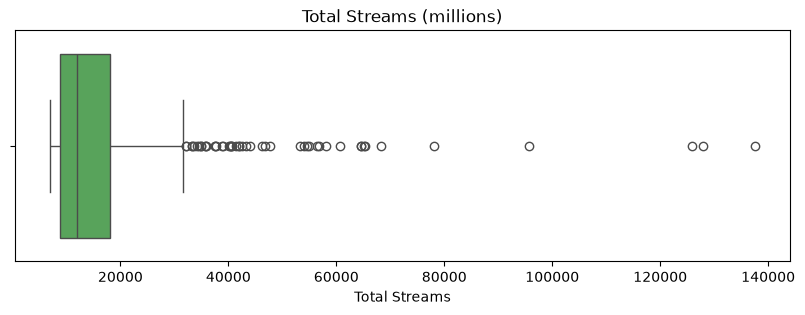

,Artist Name,Debut Year,Primary Genre
240,Frank Sinatra,1939,Pop
89,Disney,1949,Soundtrack
260,Elvis Presley,1954,Rock
465,Johnny Cash,1955,Country


In [78]:
# Distribution of Total Streams
fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=df['Total Streams'], ax=ax, color='#4CAF50')
ax.set_title('Total Streams (millions)')
plt.show()

# Artists with the oldest debut
df.nsmallest(4, 'Debut Year')[['Artist Name', 'Debut Year', 'Primary Genre']]

There are no negative values. The highest streams (Drake, Taylor Swift, Bad Bunny) are outliers statistically but they are **real values** — they are exactly the artists the project is about — so they are kept. The oldest debut years (Frank Sinatra 1939, Disney 1949, Elvis 1954, Johnny Cash 1955) are also correct.

**Summary of Q1:** 10 duplicated rows and 1 empty row removed; 33 missing stream values recovered with the stream identities; Lead/Feature of Little Mix swapped back; 22 missing `Sex` values (all groups) set to an explicit category; data types fixed; `Scotland`, `Sertanjeo` and `Nu Metal` harmonised. The clean dataset has **500 artists and no missing values**.

In [79]:
print(df.shape)
print(f"Missing values: {df.isna().sum().sum()}")

(500, 15)
Missing values: 0


**Step 9:** Reduce memory usage. We check the real memory used by the DataFrame with `memory_usage='deep'` (without it, pandas only estimates the size of the text columns) and then choose smaller data types:
- text columns with few unique values → `category`;
- `Artist ID`, `Debut Year` and `Year` are small integers (max 2026) → `int16` (range up to 32,767);
- streams have one decimal and are below 140,000 → `float32` is enough (about 7 significant digits).

In [80]:
df.info(memory_usage='deep')
memory_before = df.memory_usage(deep=True).sum() / 1024

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Artist ID              500 non-null    int64         
 1   Artist Name            500 non-null    str           
 2   Sex                    500 non-null    str           
 3   Country of Origin      500 non-null    str           
 4   Primary Language       500 non-null    str           
 5   Primary Genre          500 non-null    str           
 6   Artist Type            500 non-null    str           
 7   Debut Year             500 non-null    int64         
 8   Total Streams          500 non-null    float64       
 9   Lead Streams           500 non-null    float64       
 10  Feature Streams        500 non-null    float64       
 11  Solo Streams           500 non-null    float64       
 12  Collaborative Streams  500 non-null    float64       
 13  Update Date     

In [81]:
# Few unique values compared with 500 rows -> good candidates for category
df.select_dtypes(include='str').nunique()

Artist Name          500
Sex                    3
Country of Origin     42
Primary Language      11
Primary Genre         22
Artist Type            2
dtype: int64

In [82]:
df = df.astype({'Artist ID': 'int16', 'Debut Year': 'int16', 'Year': 'int16',
                'Sex': 'category', 'Country of Origin': 'category', 'Primary Language': 'category',
                'Primary Genre': 'category', 'Artist Type': 'category',
                'Total Streams': 'float32', 'Lead Streams': 'float32', 'Feature Streams': 'float32',
                'Solo Streams': 'float32', 'Collaborative Streams': 'float32'})

df.info(memory_usage='deep')
memory_after = df.memory_usage(deep=True).sum() / 1024
print(f"\nMemory: {memory_before:.1f} KB -> {memory_after:.1f} KB ({(1 - memory_after / memory_before) * 100:.0f}% less)")

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Artist ID              500 non-null    int16         
 1   Artist Name            500 non-null    str           
 2   Sex                    500 non-null    category      
 3   Country of Origin      500 non-null    category      
 4   Primary Language       500 non-null    category      
 5   Primary Genre          500 non-null    category      
 6   Artist Type            500 non-null    category      
 7   Debut Year             500 non-null    int16         
 8   Total Streams          500 non-null    float32       
 9   Lead Streams           500 non-null    float32       
 10  Feature Streams        500 non-null    float32       
 11  Solo Streams           500 non-null    float32       
 12  Collaborative Streams  500 non-null    float32       
 13  Update Date     

`Artist Name` stays as text because every value is unique, so `category` would not save memory.

#### 1.2 Artist profile (Q2) <a class="anchor" id="P1.2"></a>
[Back to TOC](#toc)

**Q2 a)** How many unique artists are included in the data? How many pop artists are there?

In [83]:
print(f"Unique artists (ID): {df['Artist ID'].nunique()}")
print(f"Unique artists (name): {df['Artist Name'].nunique()}")
print(f"Pop artists: {(df['Primary Genre'] == 'Pop').sum()}")
print(f"K-Pop artists (separate genre): {(df['Primary Genre'] == 'K-Pop').sum()}")

Unique artists (ID): 500
Unique artists (name): 500
Pop artists: 102
K-Pop artists (separate genre): 11


There are **500 unique artists**, and **102 have Pop as their primary genre** (113 if K-Pop were counted as Pop, but in the data it is a separate genre).

**Q2 b)** What is the most common primary genre? **Q2 c)** What is the most common country of origin?

In [84]:
print(df['Primary Genre'].value_counts().head(3), '\n')
print(df['Country of Origin'].value_counts().head(3))

Primary Genre
Hip-Hop    115
Pop        102
Rock        60
Name: count, dtype: int64 

Country of Origin
United States     265
United Kingdom     57
Mexico             27
Name: count, dtype: int64


- The most common primary genre is **Hip-Hop, with 115 artists** (just ahead of Pop with 102).
- The most common country of origin is the **United States, with 265 artists** — more than half of the dataset.

**Q2 d)** What are the top 3 most common primary languages?

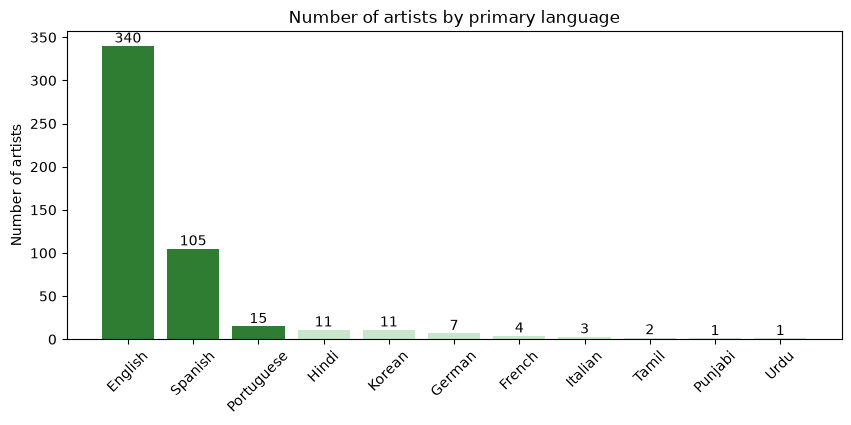

In [85]:
languages = df['Primary Language'].value_counts()

fig, ax = plt.subplots(figsize=(10, 4))
colors = ['#2E7D32' if i < 3 else '#C8E6C9' for i in range(len(languages))]  # highlight the top 3
ax.bar(languages.index, languages.values, color=colors)
ax.bar_label(ax.containers[0])
ax.set_title('Number of artists by primary language')
ax.set_ylabel('Number of artists')
plt.xticks(rotation=45)
plt.show()

The top 3 primary languages are **English (340), Spanish (105) and Portuguese (15)**. English alone represents 68% of the artists.

#### 1.3 Update dates (Q3) <a class="anchor" id="P1.3"></a>
[Back to TOC](#toc)

**Q3 a)** How many days ago were the most recent and oldest updates? On what day, month and year did they occur?

In [86]:
today = pd.Timestamp.today().normalize()
most_recent = df['Update Date'].max()
oldest = df['Update Date'].min()

print(f"Today: {today.strftime('%d %B %Y')}")
print(f"Most recent update: {most_recent.strftime('%d %B %Y')} -> {(today - most_recent).days} days ago")
print(f"Oldest update: {oldest.strftime('%d %B %Y')} -> {(today - oldest).days} days ago")

Today: 07 November 2026
Most recent update: 01 July 2026 -> 129 days ago
Oldest update: 01 July 2025 -> 494 days ago


The most recent update was on **1 July 2026** and the oldest on **1 July 2025**, exactly one year apart. The number of days is computed from the day the notebook is run (on 7 November 2026 it was 129 and 494 days ago, respectively).

**Q3 b)** Are there artists whose last update was before the end of 2025?

In [87]:
outdated = df[df['Update Date'] < '2026-01-01']
print(f"Artists with out-of-date stream counts: {len(outdated)}")
outdated[['Artist Name', 'Primary Genre', 'Update Date', 'Total Streams']]

Artists with out-of-date stream counts: 10


,Artist Name,Primary Genre,Update Date,Total Streams
109,Quavo,Hip-Hop,2025-07-01,19383.50
175,Gucci Mane,Hip-Hop,2025-07-01,14880.20
193,Grupo Frontera,Regional Mexican,2025-07-01,13999.30
260,Elvis Presley,Rock,2025-07-01,11588.80
353,Teddy Swims,Pop,2025-07-01,9177.50
381,Alejandro Fernández,Latin,2025-07-01,8617.10
387,SEVENTEEN,K-Pop,2025-07-01,8531.30
439,ScHoolboy Q,Hip-Hop,2025-07-01,7817.30
478,Kane Brown,Country,2025-07-01,7313.20
480,Grupo Menos É Mais,Latin,2025-07-01,7277.60


**10 artists** require an update: Quavo, Gucci Mane, Grupo Frontera, Elvis Presley, Teddy Swims, Alejandro Fernández, SEVENTEEN, ScHoolboy Q, Kane Brown and Grupo Menos É Mais. Their counts are one year old, so they are probably **underestimated** compared with the rest of the dataset; this should be kept in mind when ranking them.

#### 1.4 Career length and collaborations (Q4) <a class="anchor" id="P1.4"></a>
[Back to TOC](#toc)

**Q4 a)** How does the length of an artist's career impact their total streams?

Career length = year of extraction (`Year`) − `Debut Year`.

In [88]:
df['Career Length'] = df['Year'] - df['Debut Year']

# Group careers in decades to compare distributions
df['Career Group'] = pd.cut(df['Career Length'], bins=[0, 10, 20, 30, 40, 90], right=False,
                            labels=['0-9', '10-19', '20-29', '30-39', '40+'])

print(f"Pearson correlation: {df['Career Length'].corr(df['Total Streams']):.3f}")
print(f"Spearman correlation: {df['Career Length'].corr(df['Total Streams'], method='spearman'):.3f}")
df.groupby('Career Group', observed=True)['Total Streams'].agg(['count', 'median', 'mean']).round(1)

Pearson correlation: -0.068
Spearman correlation: -0.012


,count,median,mean
Career Group,,,
0-9,67,10313.50,12503.70
10-19,241,13287.00,18620.30
20-29,105,11480.40,17791.70
30-39,37,11063.60,16350.70
40+,50,9600.20,12209.00


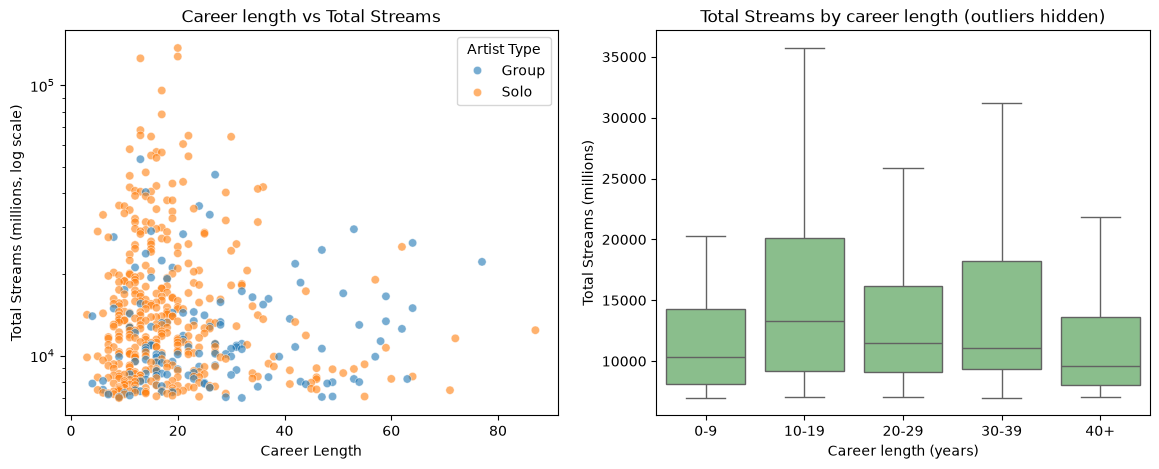

In [89]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Scatter with log scale (streams are very skewed)
sns.scatterplot(data=df, x='Career Length', y='Total Streams', hue='Artist Type', alpha=0.6, ax=ax1)
ax1.set_yscale('log')
ax1.set_title('Career length vs Total Streams')
ax1.set_ylabel('Total Streams (millions, log scale)')

# Distribution by career group
sns.boxplot(data=df, x='Career Group', y='Total Streams', color='#81C784', showfliers=False, ax=ax2)
ax2.set_title('Total Streams by career length (outliers hidden)')
ax2.set_xlabel('Career length (years)')
ax2.set_ylabel('Total Streams (millions)')
plt.show()

**Conclusion:** career length has **practically no linear or monotonic relationship** with total streams (Pearson −0.07, Spearman −0.01). A longer career does not mean more streams:
- Artists with **10–19 years** of career have the highest median (≈13,300M) — they started at the beginning of the streaming era and had time to build a catalogue.
- Artists with **40+ years** have the lowest median (≈9,600M): most of their career happened before streaming existed, so those years do not "count".
- Very recent artists (0–9 years) are also lower in total, but they reach this top-500 in much less time (see section 3.2).

So what matters is not *how long* an artist has been active, but *how much of their career overlaps with streaming*. Note that the dataset only includes the most streamed artists (survivorship bias), so this is not a conclusion about artists in general.

**Q4 b)** What are the top 5 artists that benefit the most from collaborations?

In [90]:
df['% Collaborative'] = df['Collaborative Streams'] / df['Total Streams'] * 100
df['% Solo'] = df['Solo Streams'] / df['Total Streams'] * 100

# Several artists have 100%, so ties are broken by the absolute collaborative streams
top_collab = df.sort_values(['% Collaborative', 'Collaborative Streams'], ascending=False)
print(f"Artists with 100% collaborative streams: {(df['% Collaborative'] == 100).sum()}")
top_collab[['Artist Name', 'Primary Genre', 'Total Streams', 'Collaborative Streams', '% Collaborative']].head(10).round(2)

Artists with 100% collaborative streams: 7


,Artist Name,Primary Genre,Total Streams,Collaborative Streams,% Collaborative
89,Disney,Soundtrack,22236.10,22236.10,100.00
246,Amitabh Bhattacharya,Filmi,12136.70,12136.70,100.00
277,Irshad Kamil,Filmi,11014.90,11014.90,100.00
372,DJ Luian,Reggaeton,8801.60,8801.60,100.00
447,Kumaar,Pop,7689.50,7689.50,100.00
483,Magenta,Pop,7239.70,7239.70,100.00
484,Ryan Lewis,Hip-Hop,7237.60,7237.60,100.00
392,Mambo Kingz,Reggaeton,8457.40,8456.10,99.98
63,Pritam,Pop,28543.90,28532.20,99.96
489,benny blanco,Pop,7114.10,7110.20,99.95


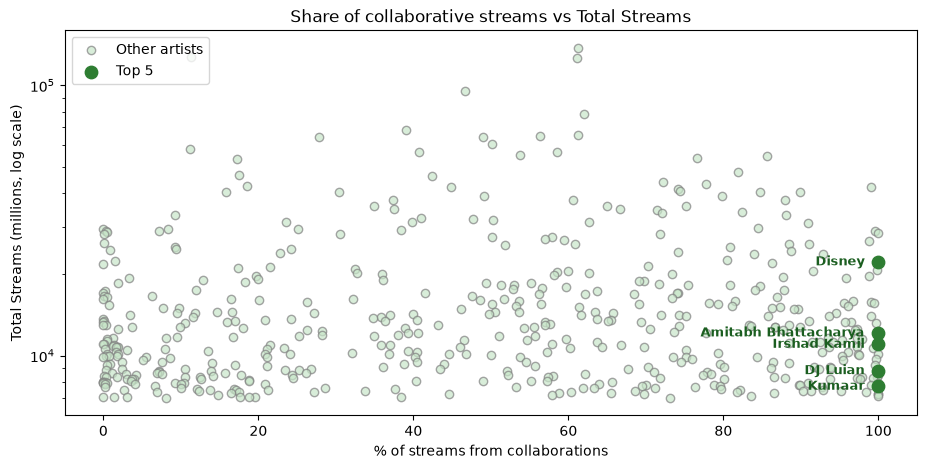

In [91]:
top5 = top_collab.head(5)

# All artists: share of collaborative streams vs total streams, with the top 5 highlighted
fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(df['% Collaborative'], df['Total Streams'], color='#C8E6C9', edgecolor='grey', alpha=0.7, label='Other artists')
ax.scatter(top5['% Collaborative'], top5['Total Streams'], color='#2E7D32', s=80, label='Top 5')
for name, y in zip(top5['Artist Name'], top5['Total Streams']):
    ax.annotate(name, (100, y), xytext=(-10, 0), textcoords='offset points', ha='right', va='center', fontsize=9,
                fontweight='bold', color='#1B5E20')
ax.set_yscale('log')
ax.set_title('Share of collaborative streams vs Total Streams')
ax.set_xlabel('% of streams from collaborations')
ax.set_ylabel('Total Streams (millions, log scale)')
ax.legend(loc='upper left')
plt.show()

The plot shows that collaboration-dependent artists exist at every level of streams, but only a few depend on them completely: seven artists get **100%** of their streams from collaborations. Breaking the tie by the absolute number of collaborative streams, the top 5 are **Disney, Amitabh Bhattacharya, Irshad Kamil, DJ Luian and Kumaar**.

These are not "typical" artists: Disney is a soundtrack label/entity, Amitabh Bhattacharya, Irshad Kamil and Kumaar are Bollywood **lyricists** (credited on songs performed by others) and DJ Luian is a **producer**. Their success exists *only* through collaborations — their profile is fundamentally different from a performer like Taylor Swift (11% collaborative).

#### 1.5 Additional insights (Q5) <a class="anchor" id="P1.5"></a>
[Back to TOC](#toc)

**Insight 1 — The genre defines how much an artist depends on collaborations.**

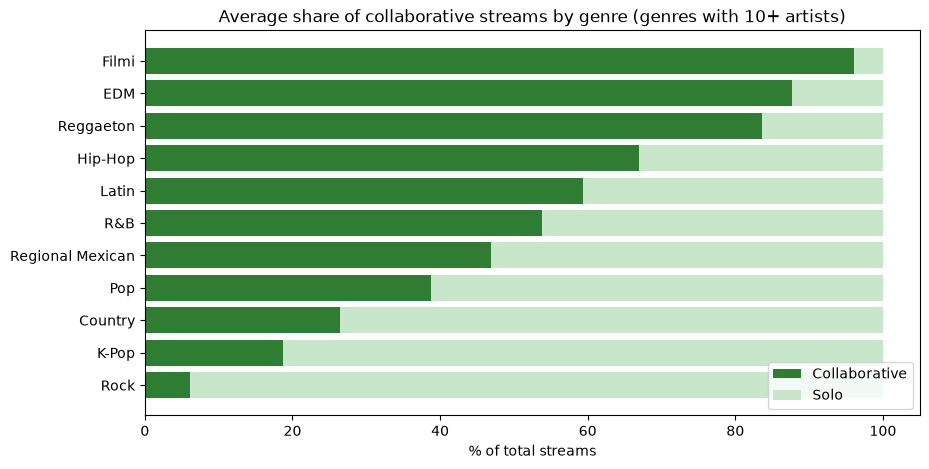

In [92]:
# Only genres with at least 10 artists, to have reliable averages
genre_counts = df['Primary Genre'].value_counts()
main_genres = genre_counts[genre_counts >= 10].index

genre_collab = (df[df['Primary Genre'].isin(main_genres)]
                .groupby('Primary Genre')[['% Collaborative', '% Solo']].mean()
                .sort_values('% Collaborative'))

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(genre_collab.index, genre_collab['% Collaborative'], color='#2E7D32', label='Collaborative')
ax.barh(genre_collab.index, genre_collab['% Solo'], left=genre_collab['% Collaborative'], color='#C8E6C9', label='Solo')
ax.set_title('Average share of collaborative streams by genre (genres with 10+ artists)')
ax.set_xlabel('% of total streams')
ax.legend(loc='lower right')
plt.show()

There is a huge gap between genres: a **Rock** artist gets on average only ~6% of streams from collaborations, while **Reggaeton (84%), EDM (88%) and Filmi (96%)** are built on them. In EDM the DJ/producer almost always works with a guest vocalist, and in Reggaeton/Hip-Hop features are part of the culture. For an artist in these genres, collaborating is not optional — it is the main path to streams.

**Insight 2 — Solo artists stream more than groups; sex makes little difference.**

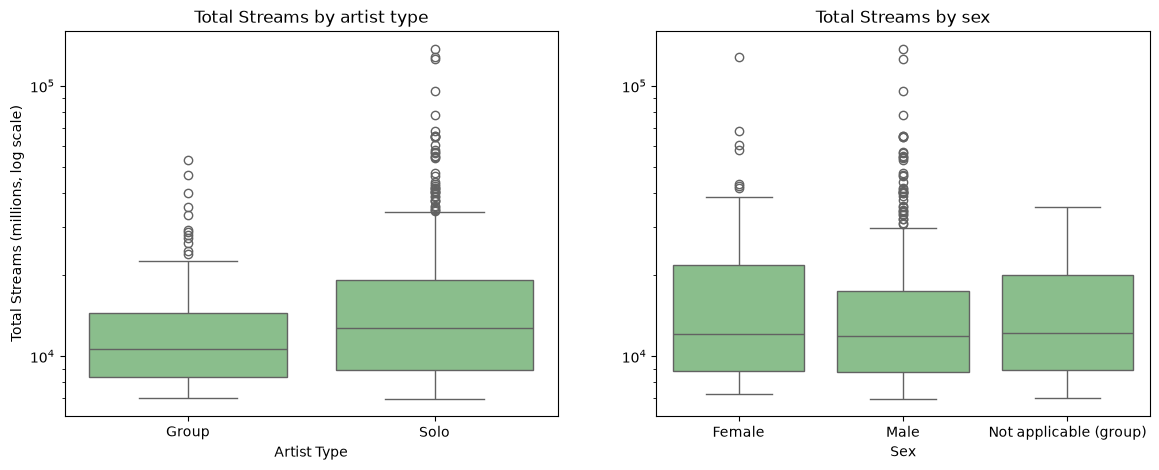

             count   median     mean
Artist Type                         
Group          127 10607.00 13290.10
Solo           373 12700.70 18018.70 

                        count   median     mean
Sex                                            
Female                     88 12097.20 18593.50
Male                      390 11837.60 16507.80
Not applicable (group)     22 12236.30 15206.40


In [93]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='Artist Type', y='Total Streams', color='#81C784', ax=ax1)
ax1.set_yscale('log')
ax1.set_title('Total Streams by artist type')
ax1.set_ylabel('Total Streams (millions, log scale)')

sns.boxplot(data=df, x='Sex', y='Total Streams', color='#81C784', ax=ax2)
ax2.set_yscale('log')
ax2.set_title('Total Streams by sex')
ax2.set_ylabel('')
plt.show()

print(df.groupby('Artist Type')['Total Streams'].agg(['count', 'median', 'mean']).round(1), '\n')
print(df.groupby('Sex')['Total Streams'].agg(['count', 'median', 'mean']).round(1))

Solo artists have a higher median (≈12,700M vs ≈10,600M) and a much higher mean (≈18,000M vs ≈13,300M): all the top artists are solo, and groups are concentrated in Rock, where streams are lower and collaborations rare (Insight 1). Regarding sex, the medians are almost identical. However, **only 88 of the 500 artists (18%) are female** — women are clearly under-represented in the top, but once they get there, they stream as much as (on average even more than) men.

**Insight 3 — Non-English artists are under-represented, and get fewer streams per artist.**

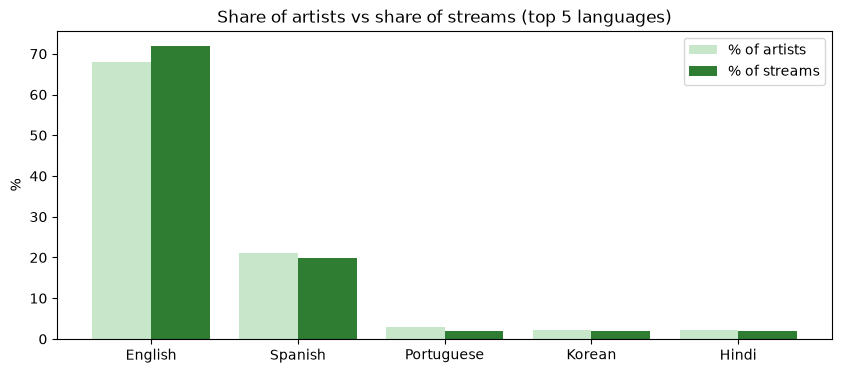

,Artists,Streams,Median,% of artists,% of streams
Primary Language,,,,,
English,340,6055232.50,12769.60,68.00,72.00
Spanish,105,1679371.25,11566.20,21.00,20.00
Portuguese,15,164439.00,10122.50,3.00,2.00
Korean,11,157338.70,8531.30,2.20,1.90
Hindi,11,157453.09,10165.00,2.20,1.90
German,7,81201.20,8906.90,1.40,1.00
French,4,41569.90,9949.50,0.80,0.50
Italian,3,26576.40,9437.30,0.60,0.30
Tamil,2,30138.20,15069.10,0.40,0.40


In [94]:
lang = df.groupby('Primary Language').agg(Artists=('Artist Name', 'count'),
                                          Streams=('Total Streams', 'sum'),
                                          Median=('Total Streams', 'median'))
lang['% of artists'] = lang['Artists'] / lang['Artists'].sum() * 100
lang['% of streams'] = lang['Streams'] / lang['Streams'].sum() * 100
lang = lang.sort_values('Artists', ascending=False)

top_lang = lang.head(5)
x = np.arange(len(top_lang))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.2, top_lang['% of artists'], width=0.4, color='#C8E6C9', label='% of artists')
ax.bar(x + 0.2, top_lang['% of streams'], width=0.4, color='#2E7D32', label='% of streams')
ax.set_xticks(x, top_lang.index)
ax.set_title('Share of artists vs share of streams (top 5 languages)')
ax.set_ylabel('%')
ax.legend()
plt.show()

lang.round(1)

English artists are 68% of the list but hold **72% of all streams**, and they have the highest median (≈12,800M). Every other language has a slightly smaller share of streams than of artists. The global streaming top is still dominated by English; the only real competitor is Spanish (21% of artists and 20% of streams), driven by Reggaeton and Latin music.

### <font color='#BFD72F'>2. Advanced Topic - Interactive Maps </font> <a class="anchor" id="P2"></a>
[Back to TOC](#toc)

#### 2.1 Web scraping <a class="anchor" id="P2.1"></a>

The goal is to obtain the birthplace (solo artists) or origin (groups) of each artist from Wikipedia, and then the coordinates of that place, **using only Wikipedia**.

Approach:
1. Start at the **Main Page** and read its search form, which gives the search URL used by the website.
2. For each artist, search the name. If the page found is not a musician (e.g. a disambiguation page like "Drake" or "Future"), try the usual Wikipedia disambiguations: *(musician)*, *(singer)*, *(rapper)*, *(band)*, ...
3. A page is accepted as a musician page if its infobox has a *Genres* or *Years active* row.
4. To **ensure the correct match**, the place found must contain the artist's `Country of Origin` from our dataset. If it does not, the next disambiguation is tried. If no page matches the country, the first musician page is kept but flagged.
5. From the infobox, read the *Born* place (inside the `birthplace` tag) or the *Origin*.
6. Open the link of the place (most specific first, e.g. the city) and read the coordinates from the `geo` tag at the top of the page.

Scraping all artists takes some minutes, so the results are saved to `data/artist_locations.csv`. If that file already exists, it is loaded instead of scraping again.

In [95]:
BASE = 'https://en.wikipedia.org'

# Wikipedia asks automated clients to identify themselves
session = requests.Session()
session.headers.update({'User-Agent': 'PDS-NOVA-IMS-student-project/1.0 (educational use)'})

# Step 1: start at the Main Page and get the search URL from its search form
main_page = BeautifulSoup(session.get(BASE + '/wiki/Main_Page').text, 'html.parser')
search_form = main_page.find('form', id='searchform')
search_url = BASE + (search_form['action'] if search_form else '/w/index.php')
print(f"Search URL: {search_url}")

Search URL: https://en.wikipedia.org/w/index.php


In [96]:
def get_soup(url, params=None):
    # Download a page and return it parsed (with a short pause to be polite to Wikipedia)
    r = session.get(url, params=params, timeout=20)
    time.sleep(0.2)
    return BeautifulSoup(r.text, 'html.parser')


def search(query):
    # Same as typing in the Main Page search box: goes directly to the article if the title exists
    return get_soup(search_url, params={'search': query, 'title': 'Special:Search', 'go': 'Go'})


def infobox_cell(soup, label):
    # Return the value cell of an infobox row (e.g. 'Born', 'Origin'), or None
    box = soup.find('table', class_='infobox')
    if box is None:
        return None
    for th in box.find_all('th', class_='infobox-label'):
        if th.get_text(' ', strip=True).lower() == label.lower():
            return th.find_next_sibling('td')
    return None


def is_musician(soup):
    return infobox_cell(soup, 'Genres') is not None or infobox_cell(soup, 'Years active') is not None

In [97]:
def clean_text(tag):
    # Remove references like [1] and hidden text, and return clean text
    for t in tag.find_all(['sup', 'style']):
        t.decompose()
    for t in tag.find_all(style=re.compile('display: ?none')):
        t.decompose()
    text = tag.get_text(' ', strip=True)
    return re.sub(r'\s+,', ',', text).strip(' ,')


def get_place(soup, artist_type):
    # Solo artists: birthplace first; groups: origin first
    born, origin = infobox_cell(soup, 'Born'), infobox_cell(soup, 'Origin')
    order = [('Born', born), ('Origin', origin)] if artist_type == 'Solo' else [('Origin', origin), ('Born', born)]

    for source, cell in order:
        if cell is None:
            continue
        if source == 'Origin':
            return cell, clean_text(cell), source
        # The birthplace is usually inside a 'birthplace' tag...
        tag = cell.find(class_='birthplace')
        # ...otherwise it is the last line of the cell (after the date)
        if tag is None:
            tag = BeautifulSoup(re.split(r'<br\s*/?>', str(cell))[-1], 'html.parser')
        text = clean_text(tag)
        if text and '(age' not in text and not re.fullmatch(r'[\d\s,()A-Za-z]*\d{4}\)?', text):
            return tag, text, source
    return None, None, None

In [98]:
# Different ways a country can be written in Wikipedia
country_alias = {
    'United States': ['United States', 'U.S.', 'US', 'USA', 'Puerto Rico'],
    'United Kingdom': ['United Kingdom', 'UK', 'U.K.', 'England', 'Scotland', 'Wales', 'Northern Ireland'],
    'South Korea': ['South Korea', 'Korea'],
    'DR Congo': ['Congo', 'Zaire'],
    'Russia': ['Russia', 'Soviet Union'],
}
us_states = ['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'Florida',
             'Georgia', 'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine',
             'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska',
             'Nevada', 'New Hampshire', 'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 'Ohio',
             'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina', 'South Dakota', 'Tennessee', 'Texas',
             'Utah', 'Vermont', 'Virginia', 'Washington', 'West Virginia', 'Wisconsin', 'Wyoming']


def country_matches(place, country):
    names = country_alias.get(country, [country])
    if country == 'United States':
        names = names + us_states  # older articles often omit 'U.S.' (e.g. 'Tupelo, Mississippi')
    return any(re.search(r'(?<!\w)' + re.escape(n) + r'(?!\w)', place) for n in names)

In [99]:
coords_cache = {}  # the same city appears for many artists, so each place page is only read once


def page_coords(soup):
    geo = soup.select_one('#coordinates .geo') or soup.select_one('.geo')
    if geo is None:
        return None
    lat, lon = geo.get_text().split(';')
    return float(lat), float(lon)


def get_coords(place_tag, place_text):
    # 1) follow the links of the place, most specific first (e.g. city before state/country)
    links = [a['href'].split('#')[0] for a in place_tag.find_all('a', href=True)
             if a['href'].startswith('/wiki/') and ':' not in a['href']]
    for href in links:
        if href not in coords_cache:
            coords_cache[href] = page_coords(get_soup(BASE + href))
        if coords_cache[href] is not None:
            return coords_cache[href]

    # 2) no link with coordinates: search the place text, dropping the first part until something is found
    parts = [p.strip() for p in place_text.split(',')]
    for i in range(len(parts)):
        query = ', '.join(parts[i:])
        if query not in coords_cache:
            coords_cache[query] = page_coords(search(query))
        if coords_cache[query] is not None:
            return coords_cache[query]
    return None, None

In [100]:
suffixes = ['', ' (musician)', ' (singer)', ' (rapper)', ' (band)', ' (group)', ' (DJ)', ' (producer)',
            ' (singer-songwriter)', ' (record producer)', ' (composer)', ' (lyricist)', ' (entertainer)']


def scrape_artist(name, artist_type, country):
    first = None  # first musician page found, kept if no page matches the country
    for suffix in suffixes:
        soup = search(name + suffix)
        if not is_musician(soup):
            continue
        tag, text, source = get_place(soup, artist_type)
        if text is None:
            continue
        url = BASE + '/wiki/' + soup.find('link', rel='canonical')['href'].split('/wiki/')[-1]
        result = {'Wiki URL': url, 'Place': text, 'Place Source': source, 'tag': tag}
        if country_matches(text, country):
            result['Country Check'] = True
            return result
        if first is None:
            first = result | {'Country Check': False}
    return first

In [ ]:
locations_file = 'data/artist_locations.csv'

if os.path.exists(locations_file):
    locations = pd.read_csv(locations_file)
    print(f"Loaded {len(locations)} artists from {locations_file}")
else:
    rows = []
    start = time.time()
    for i, artist in df.iterrows():
        row = {'Artist ID': artist['Artist ID'], 'Artist Name': artist['Artist Name']}
        try:
            result = scrape_artist(artist['Artist Name'], artist['Artist Type'], artist['Country of Origin'])
            if result is not None:
                lat, lon = get_coords(result.pop('tag'), result['Place'])
                row.update(result | {'Latitude': lat, 'Longitude': lon})
        except Exception as e:  # a single failed page should not stop the whole scraping
            print(f"Error with {artist['Artist Name']}: {e}")
        rows.append(row)
        if i % 50 == 0:
            print(f"{i}/{len(df)} artists ({time.time() - start:.0f}s)")

    locations = pd.DataFrame(rows)
    locations.to_csv(locations_file, index=False)
    print(f"Done in {time.time() - start:.0f}s")

locations.head()

0/500 artists (3s)


**Scraping results.** How many artists got a place and coordinates, and how many places agree with the country in our dataset?

In [ ]:
print(f"Artists: {len(locations)}")
print(f"With a Wikipedia page and place: {locations['Place'].notna().sum()}")
print(f"With coordinates: {locations['Latitude'].notna().sum()}")
print(f"Place matches the country of the dataset: {(locations['Country Check'] == True).sum()}")
print(locations['Place Source'].value_counts())

In [ ]:
# Artists without a place (no musician page found on Wikipedia)
locations[locations['Place'].isna()]['Artist Name'].tolist()

In [ ]:
# Places that do not agree with the dataset country -> check manually
locations[locations['Country Check'] == False].merge(df[['Artist ID', 'Country of Origin']], on='Artist ID')[
    ['Artist Name', 'Place', 'Country of Origin', 'Wiki URL']]

The artists listed above were reviewed manually. A mismatch does not always mean an error: e.g. an artist can be born in one country and be listed in the dataset under the country where the career started. When the **page itself** is wrong (a different person/band with the same name), the correct Wikipedia title can be added to the dictionary below and that artist is scraped again — still using only Wikipedia.

In [ ]:
# Artist Name -> correct Wikipedia title (fill in after checking the table above)
manual_titles = {}

for name, title in manual_titles.items():
    artist = df[df['Artist Name'] == name].iloc[0]
    soup = get_soup(BASE + '/wiki/' + title.replace(' ', '_'))
    tag, text, source = get_place(soup, artist['Artist Type'])
    if text is not None:
        lat, lon = get_coords(tag, text)
        locations.loc[locations['Artist Name'] == name, ['Wiki URL', 'Place', 'Place Source', 'Latitude', 'Longitude', 'Country Check']] = \
            [BASE + '/wiki/' + title, text, source, lat, lon, True]

if manual_titles:
    locations.to_csv(locations_file, index=False)

#### 2.2 Interactive maps <a class="anchor" id="P2.2"></a>
[Back to TOC](#toc)

**Step 1:** Join the scraped coordinates with the clean dataset.

Many artists share the same city (e.g. Los Angeles, Atlanta, London), so their markers would be exactly on top of each other and only one would be visible on hover. We add a very small random offset (≈ ±10 km) to the map position only.

In [ ]:
geo = df.merge(locations[['Artist ID', 'Place', 'Latitude', 'Longitude']], on='Artist ID').dropna(subset=['Latitude', 'Longitude'])

rng = np.random.default_rng(42)  # fixed seed so the map is reproducible
geo['lat_map'] = geo['Latitude'] + rng.uniform(-0.1, 0.1, len(geo))
geo['lon_map'] = geo['Longitude'] + rng.uniform(-0.1, 0.1, len(geo))

print(f"Artists on the map: {len(geo)} of {len(df)}")

**Map 1 — One marker per artist, sized by total streams.** Markers are coloured by genre: clicking a genre in the legend hides/shows it, and double-clicking isolates it, which lets the user explore one genre at a time.

In [ ]:
fig = px.scatter_geo(geo, lat='lat_map', lon='lon_map', size='Total Streams', color='Primary Genre',
                     hover_name='Artist Name',
                     custom_data=['Place', 'Total Streams', '% Solo', '% Collaborative', 'Primary Genre', 'Primary Language'],
                     projection='natural earth', size_max=40, opacity=0.7,
                     color_discrete_sequence=px.colors.qualitative.Alphabet)

fig.update_traces(hovertemplate='<b>%{hovertext}</b><br><br>' +
                                'Birthplace/Origin: %{customdata[0]}<br>' +
                                'Total Streams: %{customdata[1]:,.1f}M<br>' +
                                '% Solo Streams: %{customdata[2]:.2f}%<br>' +
                                '% Collaborative Streams: %{customdata[3]:.2f}%<br>' +
                                'Genre: %{customdata[4]} | Language: %{customdata[5]}<extra></extra>')

fig.update_geos(showcountries=True, countrycolor='white', landcolor='#E8EEF4', showocean=True, oceancolor='white')
fig.update_layout(title=dict(text='<b>Where do the most streamed artists come from?</b>', x=0.5, font=dict(size=20)),
                  legend_title_text='Genre', height=650, margin=dict(l=0, r=0, t=60, b=0))
fig.show()

**Map 2 — Density of streams by birthplace/origin.** Each artist contributes with its total streams (`z`), so the brightest areas are the places that generate more streams, not only more artists.

In [ ]:
fig = px.density_map(geo, lat='Latitude', lon='Longitude', z='Total Streams', radius=20,
                     hover_name='Artist Name', hover_data={'Place': True, 'Total Streams': ':,.1f', 'Latitude': False, 'Longitude': False},
                     center=dict(lat=25, lon=0), zoom=0.8, map_style='carto-positron',
                     color_continuous_scale='Plasma')

fig.update_layout(title=dict(text='<b>Global distribution of streams by birthplace/origin</b>', x=0.5, font=dict(size=20)),
                  coloraxis_colorbar=dict(title='Total Streams<br>(millions)'),
                  height=600, margin=dict(l=0, r=0, t=60, b=0))
fig.show()

**Map 3 (extra) — Streams per country.** The first two maps work at city level. To complement them, this map aggregates by country and adds a dropdown to switch between the total streams, number of artists and average streams per artist.

In [ ]:
country = df.sort_values('Total Streams', ascending=False).groupby('Country of Origin').agg(Streams=('Total Streams', 'sum'), Artists=('Artist Name', 'count'),
                                              Top=('Artist Name', 'first')).reset_index()  # sorted by streams, so 'first' is the top artist
country['Average'] = country['Streams'] / country['Artists']

fig = go.Figure()
for col, title in [('Streams', 'Total streams (M)'), ('Artists', 'Number of artists'), ('Average', 'Average streams per artist (M)')]:
    fig.add_trace(go.Choropleth(locations=country['Country of Origin'], locationmode='country names', z=np.log10(country[col]) if col != 'Artists' else country[col],
                                colorscale='Greens', visible=(col == 'Streams'), colorbar=dict(title=title + ('<br>(log10)' if col != 'Artists' else '')),
                                customdata=country[['Streams', 'Artists', 'Average', 'Top']],
                                hovertemplate='<b>%{location}</b><br>Total streams: %{customdata[0]:,.0f}M<br>' +
                                              'Artists: %{customdata[1]}<br>Average per artist: %{customdata[2]:,.0f}M<br>' +
                                              'Top artist: %{customdata[3]}<extra></extra>'))

buttons = [dict(label=label, method='update', args=[{'visible': [j == i for j in range(3)]}])
           for i, label in enumerate(['Total streams', 'Number of artists', 'Average per artist'])]
fig.update_layout(updatemenus=[dict(buttons=buttons, x=0.01, y=1.08, xanchor='left')],
                  title=dict(text='<b>Streams by country of origin</b>', x=0.5, font=dict(size=20)),
                  geo=dict(projection_type='natural earth', showframe=False), height=550, margin=dict(l=0, r=0, t=80, b=0))
fig.show()

**What the maps show:** streams are heavily concentrated in **North America** (the US East and West coasts, Atlanta, Toronto) and in the **UK**, followed by a second cluster in **Latin America** (Puerto Rico, Colombia, Mexico, Brazil). Asia (South Korea and India) and Africa (Nigeria) appear, but with much smaller weight. This matches Insight 3: the top of global streaming is dominated by English-speaking artists, with Spanish-speaking artists as the only large alternative.

### <font color='#BFD72F'>3. Data Science in Action </font> <a class="anchor" id="P3"></a>
[Back to TOC](#toc)

Total streams favour artists that have been around for a long time inside the streaming era, and they hide *how* an artist is successful. In this section we (1) create new variables that describe the type of success, (2) use them to measure the "momentum" of the streaming era and (3) build a **similar-artist recommender** that a user can use to discover and compare artists.

#### 3.1 New variables <a class="anchor" id="P3.1"></a>

In [ ]:
# Streams per year of career (career of 0 years counts as 1 to avoid dividing by 0)
df['Streams per Year'] = df['Total Streams'] / df['Career Length'].clip(lower=1)

# Share of streams as a guest artist
df['% Feature'] = df['Feature Streams'] / (df['Lead Streams'] + df['Feature Streams']) * 100

# Decade of debut
df['Debut Decade'] = (df['Debut Year'] // 10 * 10).astype(str) + 's'

# Profile of the artist, based on collaborations
df['Profile'] = pd.cut(df['% Collaborative'], bins=[0, 25, 75, 100.01], right=False,
                       labels=['Solo-driven', 'Balanced', 'Collaboration-driven'])

df[['Artist Name', 'Total Streams', 'Career Length', 'Streams per Year', '% Collaborative', '% Feature', 'Profile']].head(10).round(1)

In [ ]:
df['Profile'].value_counts()

#### 3.2 Streaming-era momentum <a class="anchor" id="P3.2"></a>
[Back to TOC](#toc)

Does a recent artist need less time to reach the top 500?

In [ ]:
fig = px.box(df.sort_values('Debut Year'), x='Debut Decade', y='Streams per Year', points='all',
             hover_name='Artist Name', log_y=True, color_discrete_sequence=['#2E7D32'],
             hover_data={'Debut Decade': False, 'Total Streams': ':,.0f', 'Streams per Year': ':,.0f'})
fig.update_layout(title=dict(text='<b>Streams per year of career by debut decade</b>', x=0.5, font=dict(size=20)),
                  yaxis_title='Streams per year (millions, log scale)', xaxis_title='Debut decade')
fig.show()

df.groupby('Debut Decade')['Streams per Year'].median().round(0)

In [ ]:
# Artists with the highest momentum
df.nlargest(10, 'Streams per Year')[['Artist Name', 'Debut Year', 'Total Streams', 'Streams per Year']].round(0)

The median number of streams per career year **grows every decade**: artists who debuted in the 2020s accumulate about 3 times more streams per year than artists from the 2000s, and around 10 times more than most artists who debuted before 1980. This confirms the conclusion of Q4a: the top is reached much faster today. Artists such as **Olivia Rodrigo, Peso Pluma and Tito Double P** are already among the 10 highest in momentum, next to Bad Bunny, Drake and Taylor Swift, despite having only a few years of career — they are the ones likely to climb the ranking in the next updates.

#### 3.3 Similar artist recommender <a class="anchor" id="P3.3"></a>
[Back to TOC](#toc)

Given an artist, the recommender finds the most similar artists in the dataset — "if you like X, you may also like...". It also helps compare an artist with peers that have a similar profile.

Each artist is described by:
- **Categorical:** genre, language, artist type, sex (one-hot encoded with `pd.get_dummies`);
- **Numeric:** total streams (log, since it is very skewed), % collaborative, % feature, career length and streams per year (log).

Numeric variables are scaled between 0 and 1 (min-max) so they all have the same weight. Genre gets weight 2 because it is the most important factor for a listener. Similarity between two artists is measured with the **cosine similarity** of their vectors (1 = identical profile).

In [ ]:
# Numeric features, min-max scaled
num = pd.DataFrame({'log Streams': np.log10(df['Total Streams']),
                    '% Collaborative': df['% Collaborative'],
                    '% Feature': df['% Feature'],
                    'Career Length': df['Career Length'],
                    'log Streams per Year': np.log10(df['Streams per Year'])})
num = (num - num.min()) / (num.max() - num.min())

# Categorical features, one-hot encoded (genre with double weight)
cat = pd.get_dummies(df[['Primary Language', 'Artist Type', 'Sex']]).astype(float)
genre = pd.get_dummies(df['Primary Genre']).astype(float) * 2

features = pd.concat([num, cat, genre], axis=1)
features.index = df['Artist Name']

# Cosine similarity: normalise each row to length 1, then the dot product gives the similarity
norm = features.div(np.sqrt((features ** 2).sum(axis=1)), axis=0)
similarity = pd.DataFrame(norm.values @ norm.values.T, index=features.index, columns=features.index)
similarity.shape

In [ ]:
def recommend(artist, n=5):
    # Most similar artists (excluding the artist itself)
    top = similarity[artist].drop(artist).nlargest(n)
    result = df.set_index('Artist Name').loc[top.index, ['Primary Genre', 'Primary Language', 'Total Streams', '% Collaborative', 'Career Length']]
    result.insert(0, 'Similarity', top.values)

    # Compare the profile of the artist with the recommendations
    compare = pd.concat([num.set_index(df['Artist Name']).loc[[artist]], num.set_index(df['Artist Name']).loc[top.index]])
    fig = go.Figure()
    for name, values in compare.iterrows():
        fig.add_trace(go.Scatterpolar(r=list(values) + [values.iloc[0]], theta=list(compare.columns) + [compare.columns[0]],
                                      name=name, line=dict(width=4 if name == artist else 1.5)))
    fig.update_layout(title=dict(text=f'<b>Artists similar to {artist}</b>', x=0.5), polar=dict(radialaxis=dict(range=[0, 1])), height=450)
    fig.show()
    return result.astype({'Total Streams': 'float64'}).round(2)  # float32 shows extra decimals

In [ ]:
recommend('Drake')

In [ ]:
recommend('Linkin Park')

In [ ]:
recommend('Bad Bunny')

The recommendations make sense from a listener's point of view: Drake is matched with other English hip-hop artists that rely heavily on features; Linkin Park with rock groups that almost never collaborate; and Bad Bunny with Spanish reggaeton artists. The radar chart shows *why* each artist was recommended and where it differs (e.g. same genre but a much shorter career or a lower volume of streams), which turns the recommender into a quick comparison tool.

To try another artist, call `recommend('Artist Name')` with any name in the dataset.

### <font color='#BFD72F'>4. Conclusions </font> <a class="anchor" id="P4"></a>
[Back to TOC](#toc)

**What makes a music artist successful on streaming?**
- **Timing more than career length.** Career length alone does not explain total streams; what matters is how much of the career happened in the streaming era. Recent artists reach the top much faster (3.2).
- **Genre defines the strategy.** In Reggaeton, EDM, Hip-Hop and Filmi, most streams come from collaborations; in Rock almost none do. Some "artists" in the top (lyricists, producers, Disney) exist only through collaborations.
- **The top is concentrated.** English-speaking, solo and US/UK artists dominate both in number and in streams; women are only 18% of the list. Latin music is the only large alternative.
- **Data limitations.** The dataset only contains the top ~500 artists (survivorship bias), 10 artists have outdated counts and some Wikipedia places could not be found or verified.